# EMD Summary Figures — Mask Frequencies, Mean IMF Oscillations & Weighted HHT

Summary of the empirical mode decomposition (EMD) analysis produced by
[`emd_analysis_comprehensive.py`](emd_analysis_comprehensive.py). That script decomposes the
L4 MUA time series into 5 intrinsic mode functions (IMFs) for every **trial** (0–9) and
**stimulus direction** (`theta0`…`theta315`), i.e. **10 trials × 8 directions = 80 recordings**,
and stores per-recording results in `core/emd_analysis_output/emd_results_trial_*_angle_*.pkl`.

This notebook aggregates across all 80 recordings and produces the following figures:

1. **Mask frequency per IMF** — box plot (median / IQR) with the individual recordings overlaid.
2. **Mean IMF oscillation** — trial-averaged IMF waveform per IMF with ± SEM shading
   (plus the mean instantaneous-amplitude envelope, which is not subject to phase cancellation).
3. **Mean IA-weighted Hilbert–Huang transform (HHT)** — mean power spectrum per IMF with ± SEM shading.
4. **Harmonic-relationship tests** — aggregated across all recordings for **every IMF pair**
   (IMF-1…4 vs IMF-5, IMF-1…3 vs IMF-4, IMF-1…2 vs IMF-3, IMF-1 vs IMF-2), to report the (lack of)
   harmonic structure between IMFs.

All figures are saved as vector **PDF** and 300-dpi **PNG** under `core/emd_analysis_output/figures/`.

> **Units note.** The `mask_freqs` stored in the pickles are already in **Hz** (they were returned by
> `emd.sift.iterated_mask_sift(..., sample_rate=fs)`); no `× fs` rescaling is applied here.

In [1]:
import os
import glob
import pickle

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ---- Publication-quality matplotlib defaults ------------------------------
mpl.rcParams.update({
    "figure.dpi": 120,          # on-screen
    "savefig.dpi": 300,         # exported raster
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,         # editable text in Illustrator/Inkscape
    "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

# ---- Per-IMF colour palette -----------------------------------------------
# The paper reserves red / blue / green / purple for other meanings, so those hue
# families are deliberately avoided here. Removing them leaves no colour-blind-safe
# *categorical* set (CVD compresses the remaining warm hues together), so we use a
# warm SEQUENTIAL ramp (YlOrBr, orange->brown) ordered by IMF: identity is carried
# by LIGHTNESS (robust to every CVD type) plus the axis labels / legend / peak
# position. One fixed colour per IMF, reused across every figure.
_ylorbr = mpl.colormaps["hsv"]
IMF_COLORS = [_ylorbr(x) for x in np.linspace(0.95, 0.05, 5)]  # IMF-1 darkest -> IMF-5 lightest
# Approximate physiological band each IMF falls in (for annotation only).
IMF_BANDS = ["gamma", "gamma", "alpha/beta", "theta", "delta"]

OUTPUT_DIR = "core/emd_analysis_output"
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(fig, name):
    '''Save a figure as both PDF (vector) and PNG (300 dpi).'''
    for ext in ("pdf", "png"):
        path = os.path.join(FIG_DIR, f"{name}.{ext}")
        fig.savefig(path)
    print(f"saved: {os.path.join(FIG_DIR, name)}.{{pdf,png}}")

print("matplotlib", mpl.__version__)


matplotlib 3.9.1


## Load and stack all EMD results

We load every `emd_results_trial_*_angle_*.pkl` file and stack the quantities we need into
arrays with a leading *recording* axis (size 80):

| array | shape | meaning |
|-------|-------|---------|
| `mask_freqs`   | `(80, 5)`        | mask frequency (Hz) per IMF |
| `imf_waveforms`| `(80, 1249, 5)`  | IMF time series |
| `imf_ia`       | `(80, 1249, 5)`  | instantaneous amplitude (envelope) per IMF |
| `spec_weighted`| `(80, 128, 5)`   | IA-weighted HHT per IMF |
| `freq_centres` | `(128,)`         | HHT frequency-bin centres (Hz) |


In [2]:
result_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "emd_results_trial_*_angle_*.pkl")))
print(f"Found {len(result_files)} result files")

mask_freqs, imf_waveforms, imf_ia, spec_weighted = [], [], [], []
trials, angles = [], []
freq_centres = None
fs = None

for fp in result_files:
    with open(fp, "rb") as f:
        r = pickle.load(f)
    if "error" in r:
        print(f"  skipping {os.path.basename(fp)} (analysis error)")
        continue
    mask_freqs.append(np.asarray(r["mask_freqs"], dtype=float))
    imf_waveforms.append(np.asarray(r["imf_data"], dtype=float))
    imf_ia.append(np.asarray(r["instantaneous_amplitude"], dtype=float))
    spec_weighted.append(np.asarray(r["spec_weighted"], dtype=float))
    trials.append(r["trial"])
    angles.append(r["angle"])
    if freq_centres is None:
        freq_centres = np.asarray(r["freq_centres"], dtype=float)
        fs = r["fs"]

mask_freqs   = np.stack(mask_freqs)      # (n_rec, 5)
imf_waveforms = np.stack(imf_waveforms)  # (n_rec, n_time, 5)
imf_ia       = np.stack(imf_ia)          # (n_rec, n_time, 5)
spec_weighted = np.stack(spec_weighted)  # (n_rec, n_freq, 5)

n_rec, n_time, n_imf = imf_waveforms.shape
time = np.arange(n_time) / fs            # seconds, relative to analysis window

print(f"n recordings : {n_rec}  ({len(set(trials))} trials x {len(set(angles))} directions)")
print(f"n IMFs       : {n_imf}")
print(f"sampling rate: {fs} Hz   |  window: {time[0]:.3f}-{time[-1]:.3f} s ({n_time} samples)")
print(f"HHT freq bins: {freq_centres.min():.2f}-{freq_centres.max():.2f} Hz ({freq_centres.size} bins)")

Found 80 result files


n recordings : 80  (10 trials x 8 directions)
n IMFs       : 5
sampling rate: 500 Hz   |  window: 0.000-2.496 s (1249 samples)
HHT freq bins: 0.39-99.61 Hz (128 bins)


In [3]:
# Per-IMF descriptive statistics for the mask frequencies (sanity table)
print(f"{'IMF':>4} {'band':>11} {'mean(Hz)':>9} {'SD':>7} {'SEM':>7} {'min':>7} {'max':>7}")
print("-" * 58)
for i in range(n_imf):
    x = mask_freqs[:, i]
    print(f"{i+1:>4} {IMF_BANDS[i]:>11} {x.mean():>9.2f} {x.std(ddof=1):>7.2f} "
          f"{x.std(ddof=1)/np.sqrt(n_rec):>7.3f} {x.min():>7.2f} {x.max():>7.2f}")
print("-" * 58)
print(f"pooled mean = {mask_freqs.mean():.3f} Hz   pooled SD (pop.) = {mask_freqs.std():.3f} Hz")
print("(compare with core/emd_analysis_output/analysis_summary.json: mean 25.051, std 25.990)")


 IMF        band  mean(Hz)      SD     SEM     min     max
----------------------------------------------------------
   1       gamma     72.92    2.23   0.250   68.01   79.68
   2       gamma     31.21    1.23   0.138   27.86   35.29
   3  alpha/beta     13.46    0.98   0.110   11.43   15.79
   4       theta      5.47    0.67   0.074    4.08    7.35
   5       delta      2.19    0.39   0.043    1.52    3.48
----------------------------------------------------------
pooled mean = 25.051 Hz   pooled SD (pop.) = 25.990 Hz
(compare with core/emd_analysis_output/analysis_summary.json: mean 25.051, std 25.990)


## Figure 1 — Mask frequency per IMF (box plot)

Distribution of the mask (carrier) frequency for each of the 5 IMFs across all 80 trial ×
direction recordings. Boxes show the median and inter-quartile range (IQR), whiskers extend to
1.5 × IQR, and the dark dots are the 80 individual recordings (jittered) so the full spread is
visible. IMFs are ordered from highest (IMF-1) to lowest (IMF-5) carrier frequency, spanning the
gamma → delta range. The y-axis is logarithmic (the frequencies span ~2–73 Hz and each IMF's
spread is small), which shows that the mask frequency of each IMF is highly consistent across the
80 recordings.


saved: core/emd_analysis_output/figures/fig1_suppl_mask_frequencies.{pdf,png}


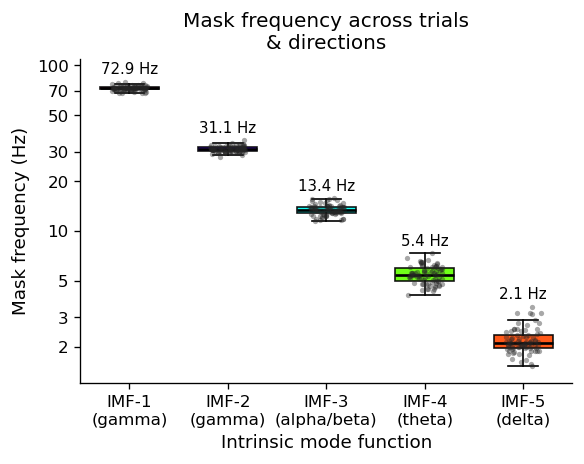

In [4]:
rng = np.random.default_rng(0)

positions = np.arange(n_imf)
data = [mask_freqs[:, i] for i in range(n_imf)]
medians = [float(np.median(d)) for d in data]

fig, ax = plt.subplots(figsize=(5, 4))

bp = ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True,
                showfliers=False, zorder=2,
                medianprops=dict(color="black", linewidth=1.6),
                boxprops=dict(linewidth=1.0, edgecolor="black"),
                whiskerprops=dict(color="black", linewidth=1.0),
                capprops=dict(color="black", linewidth=1.0))
for patch, c in zip(bp["boxes"], IMF_COLORS):
    patch.set_facecolor(c)
    patch.set_alpha(0.9)

# individual recordings, jittered
for i in range(n_imf):
    jitter = rng.uniform(-0.18, 0.18, size=n_rec)
    ax.scatter(positions[i] + jitter, mask_freqs[:, i],
               s=10, color="0.15", alpha=0.40, linewidths=0, zorder=3)

# log y-axis: mask frequencies span ~2-73 Hz, and each IMF's spread is small, so a
# log scale de-cramps the low-frequency IMFs and gives the boxes visible height.
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter
ax.set_yscale("log")
ax.set_ylim(1.2, 110)
ax.yaxis.set_major_locator(FixedLocator([2, 3, 5, 10, 20, 30, 50, 70, 100]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(ScalarFormatter())

# median labels above each box
for i, med in enumerate(medians):
    ax.text(i, mask_freqs[:, i].max() * 1.07, f"{med:.1f} Hz",
            ha="center", va="bottom", fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels([f"IMF-{i+1}\n({b})" for i, b in enumerate(IMF_BANDS)])
ax.set_ylabel("Mask frequency (Hz)")
ax.set_xlabel("Intrinsic mode function")
ax.set_title("Mask frequency across trials\n& directions")
ax.margins(x=0.04)

fig.tight_layout()
savefig(fig, "fig1_suppl_mask_frequencies")
plt.show()


## Figure 2 — Mean IMF oscillation (trial-averaged) with ± SEM shading

Each IMF waveform is averaged across the 80 recordings at every time sample; the shaded band is
the ± SEM. Because IMFs are **not perfectly phase-aligned across recordings**, the trial average
captures the *stimulus-locked (evoked)* portion of each oscillation and attenuates the
non-phase-locked part (here the trial-averaged RMS is ~17–30 % of the single-recording RMS).
The average is therefore meaningful but smaller in amplitude than any single trace.

Note each IMF is plotted on its **own y-axis scale** (amplitudes differ by an order of magnitude
across IMFs) and in its assigned colour.


saved: core/emd_analysis_output/figures/fig1_suppl_mean_imf_oscillation.{pdf,png}


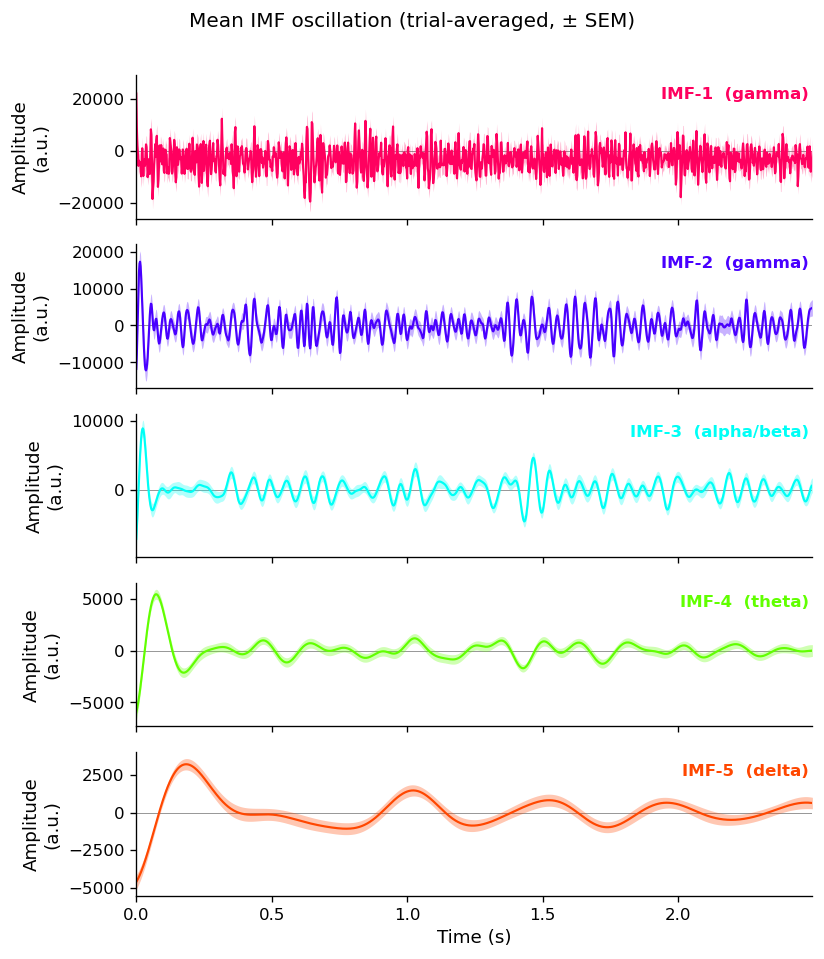

In [5]:
mean_wave = imf_waveforms.mean(axis=0)                       # (n_time, 5)
sem_wave  = imf_waveforms.std(axis=0, ddof=1) / np.sqrt(n_rec)

fig, axes = plt.subplots(n_imf, 1, figsize=(7.0, 8.0), sharex=True)
for i, ax in enumerate(axes):
    m, s = mean_wave[:, i], sem_wave[:, i]
    ax.fill_between(time, m - s, m + s, color=IMF_COLORS[i], alpha=0.30, linewidth=0)
    ax.plot(time, m, color=IMF_COLORS[i], linewidth=1.3)
    ax.axhline(0, color="0.6", linewidth=0.6, zorder=0)
    ax.set_ylabel("Amplitude\n(a.u.)")
    ax.text(0.995, 0.92, f"IMF-{i+1}  ({IMF_BANDS[i]})",
            transform=ax.transAxes, ha="right", va="top", fontsize=10,
            color=IMF_COLORS[i], fontweight="bold")
    ax.margins(x=0)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Mean IMF oscillation (trial-averaged, ± SEM)", y=0.995, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.99))
savefig(fig, "fig1_suppl_mean_imf_oscillation")
plt.show()


### Figure 2b — Mean instantaneous-amplitude (envelope) with ± SEM shading

Complementary view that is **not** subject to phase cancellation: the mean instantaneous
amplitude (Hilbert envelope) of each IMF across the 80 recordings, with ± SEM shading. This shows
the amplitude time course of each oscillation directly.


saved: core/emd_analysis_output/figures/fig2b_mean_imf_envelope.{pdf,png}


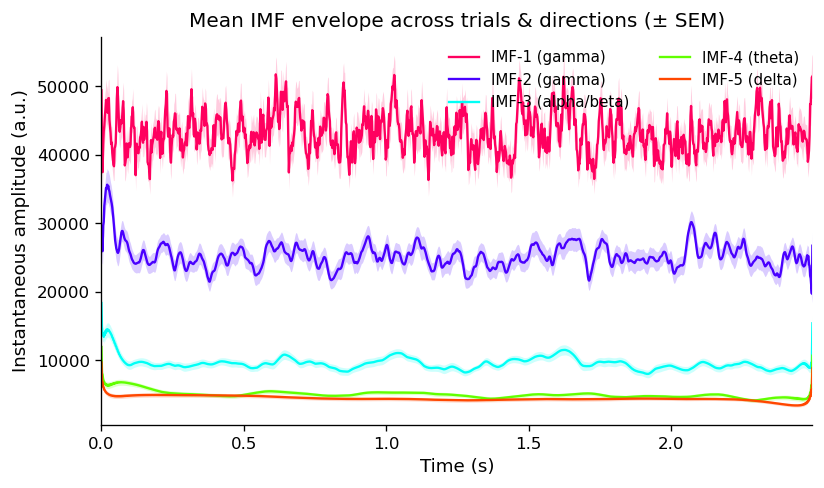

In [6]:
mean_ia = imf_ia.mean(axis=0)                       # (n_time, 5)
sem_ia  = imf_ia.std(axis=0, ddof=1) / np.sqrt(n_rec)

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for i in range(n_imf):
    m, s = mean_ia[:, i], sem_ia[:, i]
    ax.fill_between(time, m - s, m + s, color=IMF_COLORS[i], alpha=0.20, linewidth=0)
    ax.plot(time, m, color=IMF_COLORS[i], linewidth=1.4,
            label=f"IMF-{i+1} ({IMF_BANDS[i]})")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Instantaneous amplitude (a.u.)")
ax.set_title("Mean IMF envelope across trials & directions (± SEM)")
ax.margins(x=0)
ax.legend(ncol=2, loc="upper right")
fig.tight_layout()
savefig(fig, "fig2b_mean_imf_envelope")
plt.show()


## Figure 3 — Mean IA-weighted Hilbert–Huang transform with ± SEM shading

Amplitude-weighted Hilbert–Huang power spectrum for each IMF, averaged across the 80 recordings,
with ± SEM shading. Each IMF occupies a distinct frequency band whose peak matches the
corresponding mask frequency in Figure 1 (IMF-5 ≈ 2 Hz delta up to IMF-1 broadband gamma), so the
decomposition cleanly separates the signal into non-overlapping oscillatory components.


saved: core/emd_analysis_output/figures/fig2_suppl_weighted_hht.{pdf,png}


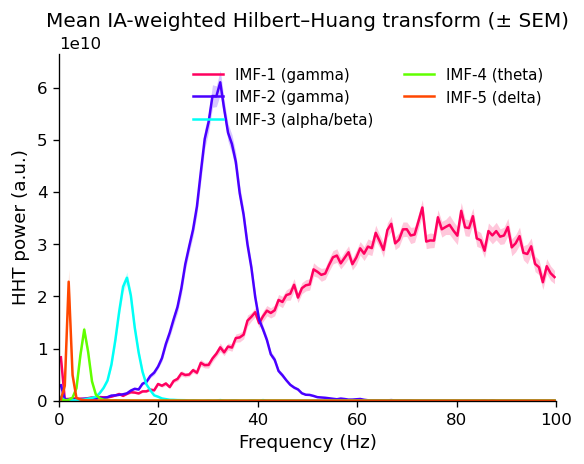

In [7]:
mean_spec = spec_weighted.mean(axis=0)                       # (n_freq, 5)
sem_spec  = spec_weighted.std(axis=0, ddof=1) / np.sqrt(n_rec)

fig, ax = plt.subplots(figsize=(5, 4))
for i in range(n_imf):
    m, s = mean_spec[:, i], sem_spec[:, i]
    ax.fill_between(freq_centres, m - s, m + s, color=IMF_COLORS[i], alpha=0.22, linewidth=0)
    ax.plot(freq_centres, m, color=IMF_COLORS[i], linewidth=1.5,
            label=f"IMF-{i+1} ({IMF_BANDS[i]})")
ax.set_xlim(0, 100)
ax.set_ylim(bottom=0)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("HHT power (a.u.)")
ax.set_title("Mean IA-weighted Hilbert–Huang transform (± SEM)")
ax.legend(ncol=2, loc="upper right")
fig.tight_layout()
savefig(fig, "fig2_suppl_weighted_hht")
plt.show()


## Harmonic-relationship tests — is any IMF a harmonic of another?

Harmonic structure could exist between any two IMFs, so we test **all 10 pairs**, always taking the
slower IMF as the potential fundamental:

| fundamental | candidate harmonics |
|---|---|
| IMF-5 | IMF-1, 2, 3, 4 |
| IMF-4 | IMF-1, 2, 3 |
| IMF-3 | IMF-1, 2 |
| IMF-2 | IMF-1 |

Following Fabus et al. (*IEEE OJSP*, 2022), two IMFs are harmonically related only if **all three**
criteria hold:

| # | Criterion | Column | Met when |
|---|-----------|--------|----------|
| 1 | **Integer frequency ratio** (IF ratio not different from nearest integer) | `Integer IF p-value` | p **>** 0.05 |
| 2 | **Consistent phase relationship** (phase–phase distance correlation) | `DistCorr p-value` | p **<** 0.05 |
| 3 | **af ratio < 1** (amplitude-ratio × frequency-ratio significantly below 1) | `af < 1 p-value` | p **<** 0.05 |

`emd_analysis_comprehensive.py` computes these with `emd.imftools.assess_harmonic_criteria(..., base_imf=k)`
for `k = 1…4` (0-indexed) on the stored instantaneous phase/frequency/amplitude (`num_segments = 18`)
and writes `core/emd_analysis_output/harmonic_criteria_all_pairs.csv`. We aggregate these across all 80
recordings and classify each IMF pairing as *harmonic* only if all three criteria are met
simultaneously.

In [8]:
import pandas as pd

ALPHA = 0.05

# One row per recording x (harmonic IMF, fundamental IMF) pair, produced by
#   python emd_analysis_comprehensive.py --harmonics-only   (or by a full run)
pairs = pd.read_csv(os.path.join(OUTPUT_DIR, "harmonic_criteria_all_pairs.csv"))

pairs["met_int"]   = pairs["Integer IF p-value"] > ALPHA   # integer frequency ratio
pairs["met_phase"] = pairs["DistCorr p-value"]   < ALPHA   # phase dependence
pairs["met_af"]    = pairs["af < 1 p-value"]     < ALPHA   # af < 1
pairs["met_all"]   = pairs["met_int"] & pairs["met_phase"] & pairs["met_af"]

grp = pairs.groupby(["fundamental_imf", "harmonic_imf"])
summary_all = pd.DataFrame({
    "freq ratio (mean)": grp["InstFreq Ratio"].mean(),
    "nearest int":       grp["InstFreq Ratio"].mean().round().astype(int),
    "integer-ratio %":   100 * grp["met_int"].mean(),
    "af (mean)":         grp["af Value"].mean(),
    "af<1 %":            100 * grp["met_af"].mean(),
    "phase-dep %":       100 * grp["met_phase"].mean(),
    "HARMONIC % (all 3)":100 * grp["met_all"].mean(),
}).round(2).sort_index(ascending=[False, True])
summary_all.index = [f"IMF-{h} vs IMF-{f}" for f, h in summary_all.index]

print(f"Recordings: {grp.size().iloc[0]}   |   IMF pairs: {len(summary_all)}")
print(summary_all.to_string())

n_all = int(pairs["met_all"].sum())
print("\n" + "=" * 66)
print(f"Pairings meeting ALL three criteria: {n_all} / {len(pairs)} ({100*n_all/len(pairs):.1f}%)")
print(f"af < 1 met in {100*pairs['met_af'].mean():.1f}% of pairings; "
      f"smallest per-pair mean af = {summary_all['af (mean)'].min():.2f} "
      f"({summary_all['af (mean)'].idxmin()})")
print("=" * 66)

summary_all.to_csv(os.path.join(OUTPUT_DIR, "harmonic_criteria_all_pairs_aggregate.csv"))
print(f"\nsaved: {os.path.join(OUTPUT_DIR, 'harmonic_criteria_all_pairs_aggregate.csv')}")

Recordings: 80   |   IMF pairs: 10
                freq ratio (mean)  nearest int  integer-ratio %  af (mean)  af<1 %  phase-dep %  HARMONIC % (all 3)
IMF-1 vs IMF-5              43.33           43            100.0     695.27     0.0         2.50                 0.0
IMF-2 vs IMF-5              18.44           18            100.0     201.47     0.0         2.50                 0.0
IMF-3 vs IMF-5               7.73            8            100.0      28.35     0.0        46.25                 0.0
IMF-4 vs IMF-5               3.10            3             95.0       5.73     0.0       100.00                 0.0
IMF-1 vs IMF-4              15.16           15            100.0     177.43     0.0         6.25                 0.0
IMF-2 vs IMF-4               6.55            7            100.0      44.30     0.0        12.50                 0.0
IMF-3 vs IMF-4               2.80            3             87.5       6.96     0.0        92.50                 0.0
IMF-1 vs IMF-3               5.64    

/tmp/ipykernel_3687298/2446614319.py:30: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig_tbl.tight_layout(pad=0.2)


saved: core/emd_analysis_output/figures/table_harmonic_criteria_all_pairs.pdf


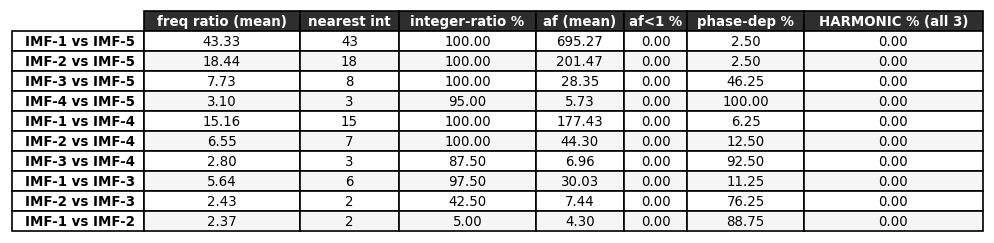

In [9]:
# Save the all-pairs summary as a standalone PDF table (Illustrator-ready).
# pdf.fonttype=42 is already set globally so all text is editable in Illustrator.
tbl_df = summary_all.reset_index(names="pair")
cell_text = [[f"{v:.2f}" if isinstance(v, float) else str(v) for v in row]
             for row in tbl_df.drop(columns="pair").itertuples(index=False)]

row_height = 0.10   # inches per row
header_h   = 0.14   # header row taller for wrapped labels
fig_w      = 1.52   # inches; columns auto-sized below

fig_tbl, ax_tbl = plt.subplots(figsize=(fig_w, header_h + len(tbl_df) * row_height + 0.10))
ax_tbl.axis("off")
tbl = ax_tbl.table(cellText=cell_text, rowLabels=list(tbl_df["pair"]),
                   colLabels=list(summary_all.columns),
                   cellLoc="center", rowLoc="left", loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.auto_set_column_width(list(range(summary_all.shape[1])))

# Style header row, row-label column and alternate data row shading
for j in range(summary_all.shape[1]):
    tbl[0, j].set_facecolor("#2e2e2e")
    tbl[0, j].set_text_props(color="white", fontweight="bold")
for i in range(1, len(tbl_df) + 1):
    tbl[i, -1].set_text_props(fontweight="bold")
    bg = "#f5f5f5" if i % 2 == 0 else "white"
    for j in range(summary_all.shape[1]):
        tbl[i, j].set_facecolor(bg)

fig_tbl.tight_layout(pad=0.2)
pdf_path = os.path.join(FIG_DIR, "table_harmonic_criteria_all_pairs.pdf")
fig_tbl.savefig(pdf_path, bbox_inches="tight")
print(f"saved: {pdf_path}")
plt.show()

### Figure 4 — Harmonic criteria for every IMF pair

Each panel is a pair matrix: rows are the candidate harmonic (faster IMF), columns the potential
fundamental (slower IMF); only pairs with the fundamental slower than the harmonic are defined. The
first four panels give the percentage of the 80 recordings meeting each criterion (and all three
jointly); the integer-ratio panel also prints the mean instantaneous-frequency ratio (×). The last
panel is the mean af ratio on a log colour scale; a harmonic requires af < 1.

**Reading the integer-ratio panel.** That criterion is a *non-significance* test (p > 0.05 against the
nearest integer). For large frequency ratios (≳ 5) the segment-to-segment spread of the ratio is
large, so the test passes almost trivially — a high percentage there is not by itself evidence of an
integer ratio. The informative pairs are the adjacent ones (ratio ≈ 2–3).

saved: core/emd_analysis_output/figures/fig1_suppl_harmonic_criteria_all_pairs.{pdf,png}


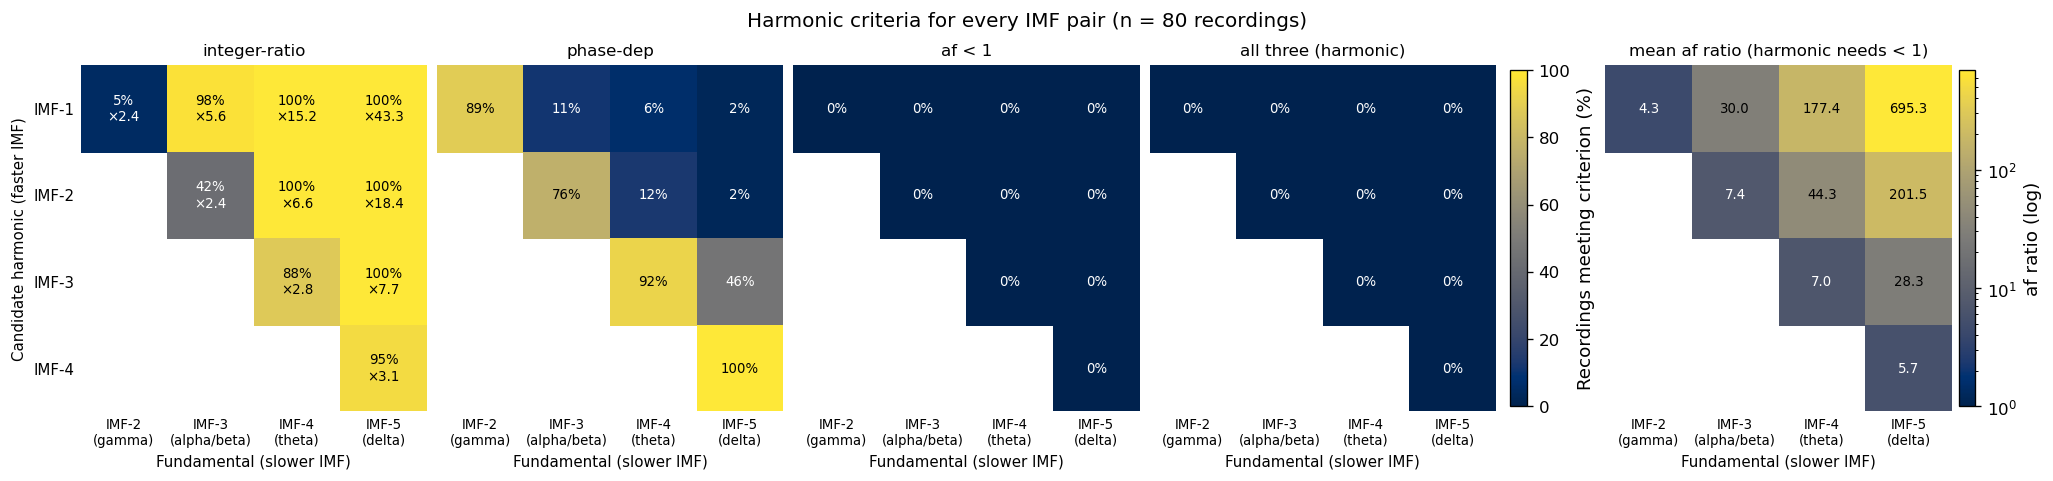

In [10]:
from matplotlib.colors import LogNorm

imfs_h = np.arange(1, n_imf)        # candidate harmonic (rows): IMF-1..IMF-4
imfs_f = np.arange(2, n_imf + 1)    # fundamental (columns):     IMF-2..IMF-5

def pair_matrix(col):
    '''Mean of `col` across recordings as a (harmonic IMF x fundamental IMF) matrix (NaN where f <= h).'''
    M = np.full((imfs_h.size, imfs_f.size), np.nan)
    for (f, h), v in grp[col].mean().items():
        M[h - 1, f - 2] = v
    return M

ratio_M = pair_matrix("InstFreq Ratio")
pct_panels = [("integer-ratio", 100 * pair_matrix("met_int")),
              ("phase-dep",     100 * pair_matrix("met_phase")),
              ("af < 1",        100 * pair_matrix("met_af")),
              ("all three (harmonic)", 100 * pair_matrix("met_all"))]
af_M = pair_matrix("af Value")

cmap = mpl.colormaps["cividis"]

def heatmap(ax, M, **kw):
    '''Draw M as vector cells (cell (i, j) centred at (j + 0.5, i + 0.5), NaN cells left empty).
    pcolormesh rather than imshow: imshow embeds a low-bit indexed-colour raster that Illustrator
    mis-renders (every cell takes a single palette colour).'''
    mesh = ax.pcolormesh(np.ma.masked_invalid(M), edgecolors="face", linewidth=0.3, **kw)
    ax.set_xlim(0, M.shape[1])
    ax.set_ylim(M.shape[0], 0)
    ax.set_aspect("equal")
    return mesh

def style_axis(ax, first):
    ax.set_xticks(np.arange(imfs_f.size) + 0.5)
    ax.set_xticklabels([f"IMF-{f}\n({IMF_BANDS[f-1]})" for f in imfs_f], fontsize=8)
    ax.set_yticks(np.arange(imfs_h.size) + 0.5)
    ax.set_yticklabels([f"IMF-{h}" for h in imfs_h] if first else [], fontsize=9)
    ax.set_xlabel("Fundamental (slower IMF)", fontsize=9)
    if first:
        ax.set_ylabel("Candidate harmonic (faster IMF)", fontsize=9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.9), constrained_layout=True)

# ---- % of recordings meeting each criterion --------------------------------
for k, (name, M) in enumerate(pct_panels):
    ax = axes[k]
    im_pct = heatmap(ax, M, cmap=cmap, vmin=0, vmax=100)
    for h in range(imfs_h.size):
        for f in range(imfs_f.size):
            v = M[h, f]
            if np.isnan(v):
                continue
            txt = f"{v:.0f}%"
            if name == "integer-ratio":
                txt += f"\n×{ratio_M[h, f]:.1f}"       # mean IF ratio for context
            ax.text(f + 0.5, h + 0.5, txt, ha="center", va="center", fontsize=8,
                    color="white" if v < 50 else "black")
    ax.set_title(name, fontsize=10)
    style_axis(ax, first=(k == 0))
fig.colorbar(im_pct, ax=axes[:4], shrink=0.85, pad=0.01,
             label="Recordings meeting criterion (%)")

# ---- mean af ratio, log colour scale ---------------------------------------
ax = axes[4]
im_af = heatmap(ax, af_M, cmap=cmap, norm=LogNorm(vmin=1, vmax=np.nanmax(af_M)))
for h in range(imfs_h.size):
    for f in range(imfs_f.size):
        v = af_M[h, f]
        if not np.isnan(v):
            ax.text(f + 0.5, h + 0.5, f"{v:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if v < np.sqrt(np.nanmax(af_M)) else "black")
ax.set_title("mean af ratio (harmonic needs < 1)", fontsize=10)
style_axis(ax, first=False)
fig.colorbar(im_af, ax=ax, shrink=0.85, pad=0.02, label="af ratio (log)")

fig.suptitle(f"Harmonic criteria for every IMF pair (n = {pairs[['trial', 'angle']].drop_duplicates().shape[0]} recordings)",
             fontsize=12)
savefig(fig, "fig1_suppl_harmonic_criteria_all_pairs")
plt.show()

## Notes & data provenance

- **Source:** 80 pickles in `core/emd_analysis_output/` (10 trials × 8 directions), produced by
  `emd_analysis_comprehensive.py` from the L4 MUA-power signal
  (`dg_all_dirs_mua_power_layer_L4only_silence_inh`, `sample_rate = 500 Hz`).
- **Aggregation:** all statistics are computed across the 80 recordings; shading / error bars are
  **± SEM** (`SD / sqrt(80)`), matching the requested "SE" convention.
- **Mask-frequency units:** already in Hz in the pickles — no `× fs` rescaling.
- **Phase caveat (Figure 2):** trial-averaged waveforms reflect the phase-locked (evoked)
  component; the envelope view (Figure 2b) avoids phase cancellation.
- **Harmonic tests (Figure 4):** criteria from `emd.imftools.assess_harmonic_criteria` for all 10 IMF
  pairs (slower IMF as fundamental), from `core/emd_analysis_output/harmonic_criteria_all_pairs.csv`
  (`python emd_analysis_comprehensive.py --harmonics-only` recomputes it from the pickles without
  re-running the sift). No pair meets all three criteria in any recording; adjacent pairs are
  phase-dependent (76–100 %) with IF ratios ≈ 2.4–3.1, but af stays ≥ 4 (af < 1 never met).
  Aggregated table saved to `core/emd_analysis_output/harmonic_criteria_all_pairs_aggregate.csv`.
- **Colour palette:** warm sequential ramp (YlOrBr) — the paper's reserved red/blue/green/purple are
  avoided; IMF identity is carried by lightness plus labels/legend.
- **Outputs:** vector PDF + 300-dpi PNG in `core/emd_analysis_output/figures/`.